# First Practical Assignment

## Data Science and Engineering

### DESIGN OF A PARALLELISABLE AND SCALABLE IMAGE FILTERING FUNCTION

**Full name:** ANTONIA ESPERANZA LUENGO SILVA
    
**NIA:** 100613380

In [1]:
import numpy as np
import multiprocess as mp
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cProfile

In [2]:
# Librerias extra
import ctypes
from multiprocess.pool import ThreadPool

In [3]:
F_IMAGE1="Test Images/cloudsonjupi.jpg"
F_IMAGE2="Test Images/chess.jpg"

In [4]:
image1= np.array(Image.open(F_IMAGE1))
image2= np.array(Image.open(F_IMAGE2))

In [5]:
NUMPROCESS=4

# WRITE YOUR CODE AFTER THIS CELL

After this cell, use the preloaded image defined in the F_IMAGE variable, select two predefined filters, and apply them to the image using NUMPROCESS processors. Check the results.


In [6]:
# YOUR CODE STARTS HERE

In [7]:
# Function to limit a value between a lower and upper bound.Boundary replication.
def clamp(value, lower, upper):
    return max(lower, min(value, upper))

# Global variables. Each pararel worker will have acces o these shared memory buffers.
shared_input_img = None
shared_output_img = None
shared_img_shape = None

# Executes when a new worker process is created. It initializes the global variables
def init_worker(input_buffer, output_buffer, shape):
    global shared_input_img, shared_output_img, shared_img_shape
    shared_input_img = input_buffer # asign memory block to the global variable
    shared_output_img = output_buffer
    shared_img_shape = shape

# Filter a range of rows using boundary replication. Each worker process will execute this function.
def worker_filter(start_row, end_row, kernel):
    height, width, channels = shared_img_shape # Get the shape of the image from the global variable
    input_np = np.frombuffer(shared_input_img, dtype=np.uint8).reshape(shared_img_shape) # Create a numpy array view of the shared memory buffer
    output_np = np.frombuffer(shared_output_img, dtype=np.float64).reshape(shared_img_shape)
    pad_h, pad_w = kernel.shape[0] // 2, kernel.shape[1] // 2 # Calculates the radius of the mask
    
    for row in range(start_row, end_row): # Iterate over the assigned rows for this worker, all channels and columns.
        for column in range(width):
            for channel in range(channels):
                accumulator = 0.0 # muliply the neighbor pixel by the corresponding mask coefficient and accumulate the result. In float to avoid overflow.
                for i in range(-pad_h, pad_h + 1):
                    source_row = clamp(row + i, 0, height - 1) # On the fly boundary replication. Prevents black borders.
                    for j in range(-pad_w, pad_w + 1):
                        source_column = clamp(column + j, 0, width - 1)
                        accumulator += (float(input_np[source_row, source_column, channel]) * kernel[i + pad_h, j + pad_w])
                output_np[row, column, channel] = accumulator

# verify that the mask is a 2D matrix with odd dimensions between 1x1 and 5x5, and that all coefficients are finite numbers.
def _validate_mask(filter_mask): 
    mask = np.asarray(filter_mask, dtype=np.float64)
    if mask.ndim != 2:
        raise ValueError("The mask must be a two-dimensional matrix.")
    rows, columns = mask.shape
    if not (1 <= rows <= 5 and 1 <= columns <= 5) or rows % 2 == 0 or columns % 2 == 0:
        raise ValueError("The mask must have odd dimensions between 1x1 and 5x5.")
    if not np.all(np.isfinite(mask)):
        raise ValueError("The mask coefficients must be finite numbers.")
    return mask

# Orquestador
def image_filter(
    image: np.ndarray,
    filter: np.ndarray,
    numprocs: int,
    is_conv: int,
    norm: int,
) -> np.ndarray:
  if isinstance(image, str):
    image = np.array(Image.open(image))
  image_array = np.asarray(image)

# Validate input parameters
  if image_array.ndim not in (2, 3) or image_array.size == 0:
    raise ValueError("The image must be a non-empty 2D or 3D array.")
  if image_array.ndim == 3 and image_array.shape[2] not in (1, 3, 4):
    raise ValueError("The image must have one, three, or four channels.")
  if not isinstance(numprocs, (int, np.integer)) or numprocs < 1:
    raise ValueError("numprocs must be a positive integer.")
  if is_conv not in (0, 1) or norm not in (0, 1):
    raise ValueError("is_conv and norm must be either 0 or 1.")

# Validate the filter mask
  mask = _validate_mask(filter)
  original_was_grayscale = image_array.ndim == 2 # If the image is grayscale, add a new axis to make it 3D for consistent processing.
  if original_was_grayscale: 
    image_array = image_array[:, :, np.newaxis]

  image_uint8 = np.clip(image_array, 0, 255).astype(np.uint8, copy=False) # Clip the image to the range [0, 255] and convert it to uint8.
  height, width, channels = image_uint8.shape

  if is_conv == 1: # Flip the mask for convolution. In convolution, the kernel is flipped both horizontally and vertically before applying it to the image.
    mask = np.flip(mask, axis=(0, 1))

  mask_sum = float(mask.sum()) 
  if norm == 1 and not np.isclose(mask_sum, 0.0): # Normalize the mask so that its sum equals 1.
    mask = mask / mask_sum

  input_buffer = mp.RawArray(ctypes.c_uint8, image_uint8.size) # Create a shared memory buffer for the input image.
  output_buffer = mp.RawArray(ctypes.c_double, image_uint8.size) 

  np.frombuffer(input_buffer, dtype=np.uint8)[:] = image_uint8.ravel() # Copy the input image data into the shared memory buffer.

  # Determine the number of processes to use, which is the minimum between the requested number of processes and the image height.
  process_count = min(int(numprocs), height)
  row_ranges = []
  for process_index in range(process_count):
    start = (process_index * height) // process_count
    end = ((process_index + 1) * height) // process_count
    row_ranges.append((start, end, mask))

  # initialize the process, calls init_worker on each one to set up the shared memory. Then calls worker filter sendind each process they 
  # assigned row range and the mask. The results are stored in the shared output buffer.
  with mp.Pool(
      processes=process_count,
      initializer=init_worker,
      initargs=(input_buffer, output_buffer, image_uint8.shape),
  ) as pool:
    pool.starmap(worker_filter, row_ranges)

  # reshape to original
  result = np.frombuffer(output_buffer, dtype=np.float64).reshape(
      image_uint8.shape
  ).copy()

  # If the mask sum is zero, apply linear rescaling independently for each channel to avoid division by zero. Otherwise, clip the result to the range [0, 255].
  if np.isclose(mask_sum, 0.0):
    res_scaled = np.zeros_like(result)
    for c in range(channels):
      chan_vals = result[:, :, c]
      minimum, maximum = chan_vals.min(), chan_vals.max()
      if np.isclose(maximum, minimum):
        res_scaled[:, :, c] = 0.0
      else:
        res_scaled[:, :, c] = (
            255.0 * (chan_vals - minimum) / (maximum - minimum)
        )
    result = res_scaled
  else:
    result = np.clip(result, 0, 255)

  result_uint8 = np.rint(result).astype(np.uint8)
  return result_uint8[:, :, 0] if original_was_grayscale else result_uint8

# Applies two filters independently and concurrently to the original image. It uses a ThreadPool to avoid nested daemon process errors, 
# allowing the internal image_filter function to instantiate its own multiprocessing Pool for heavy processing.
def parallel_filtering(image: np.ndarray, filter1: np.ndarray, filter2: np.ndarray,
                       numprocs: int, is_conv: int, norm: int) -> tuple:
    """Apply two filters independently and concurrently to the original image."""
    if isinstance(image, str):
        image = np.array(Image.open(image))
        
    # We use ThreadPool to avoid nested daemon process errors.
    # this allows the internal image_filter function to instantiate its own multiprocessing Pool for heavy processing.
    with ThreadPool(processes=2) as pool:
        task1 = pool.apply_async(image_filter, args=(image, filter1, numprocs, is_conv, norm))
        task2 = pool.apply_async(image_filter, args=(image, filter2, numprocs, is_conv, norm))
        return task1.get(), task2.get()

In [8]:
F_IMAGE1 = image1
F_IMAGE2 = image2
#YOUR CODE MUST END HERE

# EVALUATION

In the following cells, we will call your functions to evaluate them.

In [9]:
filter_mask_id =np.array([
    [0,0,0,0,0],
    [0,0,0,0,0],
    [0,0,1,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
])

In [10]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

CPU times: user 3 μs, sys: 1 μs, total: 4 μs
Wall time: 5.25 μs


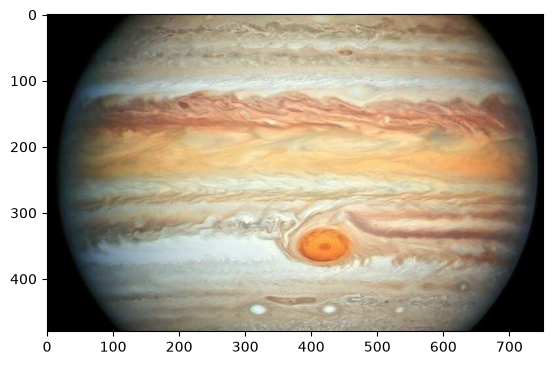

In [11]:
plt.figure()
plt.imshow(filtered_image1)

In [12]:
print(f"Identity Filter Works {np.allclose(F_IMAGE1,filtered_image1)}")

Identity Filter Works True


In [13]:
_statistics = %timeit -n 5 -r 2 -o image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

4.48 s ± 11.8 ms per loop (mean ± std. dev. of 2 runs, 5 loops each)


In [14]:
print(_statistics)

4.48 s ± 11.8 ms per loop (mean ± std. dev. of 2 runs, 5 loops each)


In [15]:
print(vars(_statistics))

{'loops': 5, 'repeat': 2, 'best': 4.470232580200081, 'worst': 4.493840936600009, 'all_runs': [22.469204683000044, 22.351162901000407], 'compile_time': 5.900000000003125e-05, '_precision': 3, 'timings': [4.493840936600009, 4.470232580200081]}


# CASCADE FILTERING

In [16]:
filter_h=np.array([
    [1,0,-1],
    [2,0,-2],
    [1,0,-1]
])
filter_v=np.array([
    [1,2,1],
    [0,0,0],
    [-1,-2,-1]
])

In [17]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_h,NUMPROCESS,1,1)
filtered_image2 = image_filter(filtered_image1,filter_v,NUMPROCESS,1,1)

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 4.05 μs


# PARALLEL FILTERING

In [18]:
%time
(filterd_image1,filtered_image2)=parallel_filtering(F_IMAGE1, filter_h, filter_v, NUMPROCESS, 1,1)

CPU times: user 1 μs, sys: 0 ns, total: 1 μs
Wall time: 5.48 μs


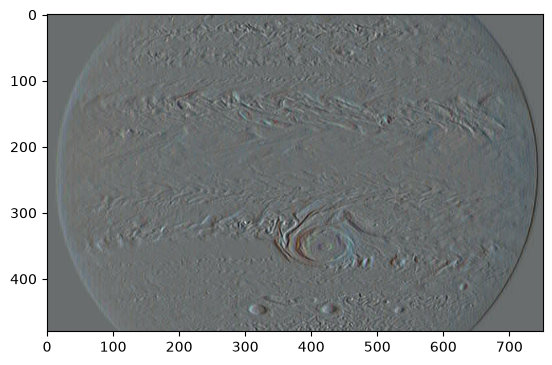

In [19]:
plt.figure()
plt.imshow(filtered_image1)

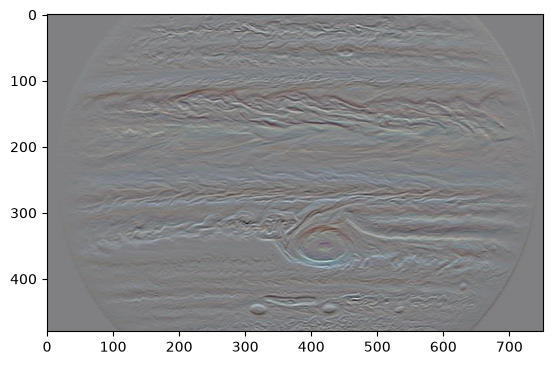

In [20]:
plt.figure()
plt.imshow(filtered_image2)

# Visualisation
In these final cells, we take the filtered images stored in the multiprocessing.Vector variables filtered_image1_VECTOR and filtered_image2_VECTOR, convert them to NumPy arrays with the same shapes as the original images, and display the results.

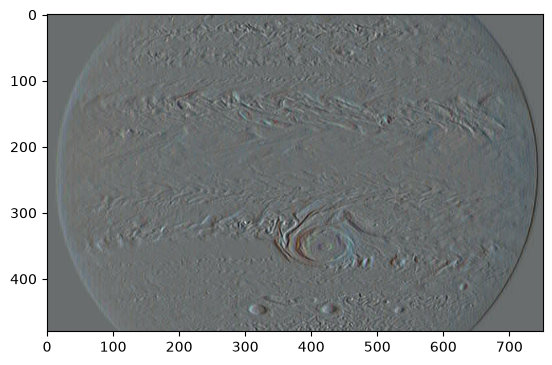

In [21]:
plt.figure()
plt.imshow(filtered_image1)

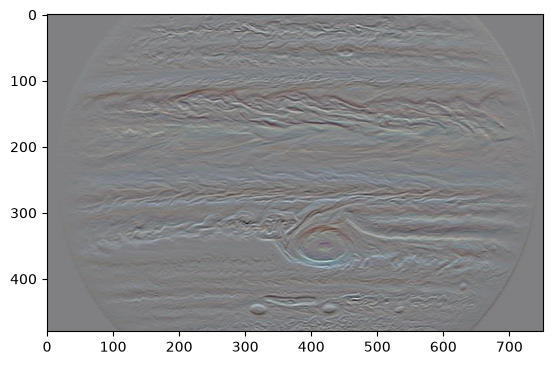

In [22]:
plt.figure()
plt.imshow(filtered_image2)

# ADD YOUR ADDITIONAL TESTS, ANALYSIS AND CONCLUSIONS AFTER THIS CELL

## Additional Tests

In [23]:
# Identity 3x3 mask
print("--- Identity mask ---")
identity = np.zeros((3, 3), dtype=float)
identity[1, 1] = 1
identity_result = image_filter(F_IMAGE1, identity, NUMPROCESS, 0, 0)
print("Pixel-by-pixel identity:", np.array_equal(F_IMAGE1, identity_result))

# Create image with constant value 128 and apply a 5x5 averaging mask. The result should be the same constant value, 
# including the borders due to replicated boundary handling (no black borders).
print("\n--- Constant image and replicated boundary ---")
constant_image = np.full((12, 12, 3), 128, dtype=np.uint8)
constant_result = image_filter(constant_image, np.ones((5, 5)) / 25, NUMPROCESS, 0, 0)
print("All pixels, including borders, equal 128:", np.all(constant_result == 128))
print("Top-left replicated-boundary value:", constant_result[0, 0, 0])

# Create a bright image with pixel values of 250 and apply a sharpening mask. 
# The result should not have any dark pixels (values below 250) due to saturation.
print("\n--- Bright image and saturation ---")
bright_image = np.full((12, 12, 3), 250, dtype=np.uint8)
sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float)
bright_result = image_filter(bright_image, sharpen, NUMPROCESS, 0, 0)
print("No dark pixels after sharpening:", bright_result.min() >= 250)

# Validate that the function correctly rejects invalid masks.
print("\n--- Mask validation ---")
for invalid_mask in (np.ones((2, 3)), np.ones((7, 7))):
    try:
        image_filter(F_IMAGE1, invalid_mask, NUMPROCESS, 0, 0)
    except ValueError as error:
        print("Rejected invalid mask:", error)

# Apply three different masks to a real image.
print("\n--- Three masks on a real image ---")
gaussian = np.array([[1, 4, 6, 4, 1], [4, 16, 24, 16, 4],
                     [6, 24, 36, 24, 6], [4, 16, 24, 16, 4],
                     [1, 4, 6, 4, 1]], dtype=float) / 256
laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=float)
parallel_gaussian_laplacian = parallel_filtering(F_IMAGE1, gaussian, laplacian, NUMPROCESS, 0, 0)
smoothed = image_filter(F_IMAGE1, gaussian, NUMPROCESS, 0, 0)
cascade_gaussian_laplacian = image_filter(smoothed, laplacian, NUMPROCESS, 0, 0)
sharpened = image_filter(F_IMAGE1, sharpen, NUMPROCESS, 0, 0)
print("Parallel outputs:", [result.shape for result in parallel_gaussian_laplacian])
print("Cascade output:", cascade_gaussian_laplacian.shape)
print("Gaussian range:", int(parallel_gaussian_laplacian[0].min()), int(parallel_gaussian_laplacian[0].max()))
print("Laplacian range after rescaling:", int(parallel_gaussian_laplacian[1].min()), int(parallel_gaussian_laplacian[1].max()))
print("Sharpen range after saturation:", int(sharpened.min()), int(sharpened.max()))


# Comparison with library filtering function
from scipy.ndimage import uniform_filter

# Create a 3x3 averaging mask and apply our image_filter function to the first test image.
mean_mask_3x3 = np.ones((3, 3), dtype=float) / 9.0
our_filtered = image_filter(F_IMAGE1, mean_mask_3x3, NUMPROCESS, 0, 1)

# Use scipy's uniform_filter to apply a 3x3 averaging filter to the same image. 
# The uniform_filter function automatically handles boundary conditions, so we don't need to worry about that.
if F_IMAGE1.ndim == 3:
    scipy_filtered = np.stack([
        uniform_filter(F_IMAGE1[:, :, c].astype(float), size=3, mode='nearest')
        for c in range(F_IMAGE1.shape[2])
    ], axis=-1)
else:
    scipy_filtered = uniform_filter(F_IMAGE1.astype(float), size=3, mode='nearest')

scipy_filtered_uint8 = np.clip(np.rint(scipy_filtered), 0, 255).astype(np.uint8)

# Calculate the maximum absolute difference between our filtered image and the scipy filtered image.
max_difference = np.max(np.abs(our_filtered.astype(int) - scipy_filtered_uint8.astype(int)))
print(f"\n--- Library Comparison (scipy) ---")
print(f"Maximum absolute difference: {max_difference}")


--- Identity mask ---
Pixel-by-pixel identity: True

--- Constant image and replicated boundary ---
All pixels, including borders, equal 128: True
Top-left replicated-boundary value: 128

--- Bright image and saturation ---
No dark pixels after sharpening: True

--- Mask validation ---
Rejected invalid mask: The mask must have odd dimensions between 1x1 and 5x5.
Rejected invalid mask: The mask must have odd dimensions between 1x1 and 5x5.

--- Three masks on a real image ---
Parallel outputs: [(480, 751, 3), (480, 751, 3)]
Cascade output: (480, 751, 3)
Gaussian range: 0 255
Laplacian range after rescaling: 0 255
Sharpen range after saturation: 0 255

--- Library Comparison (scipy) ---
Maximum absolute difference: 0


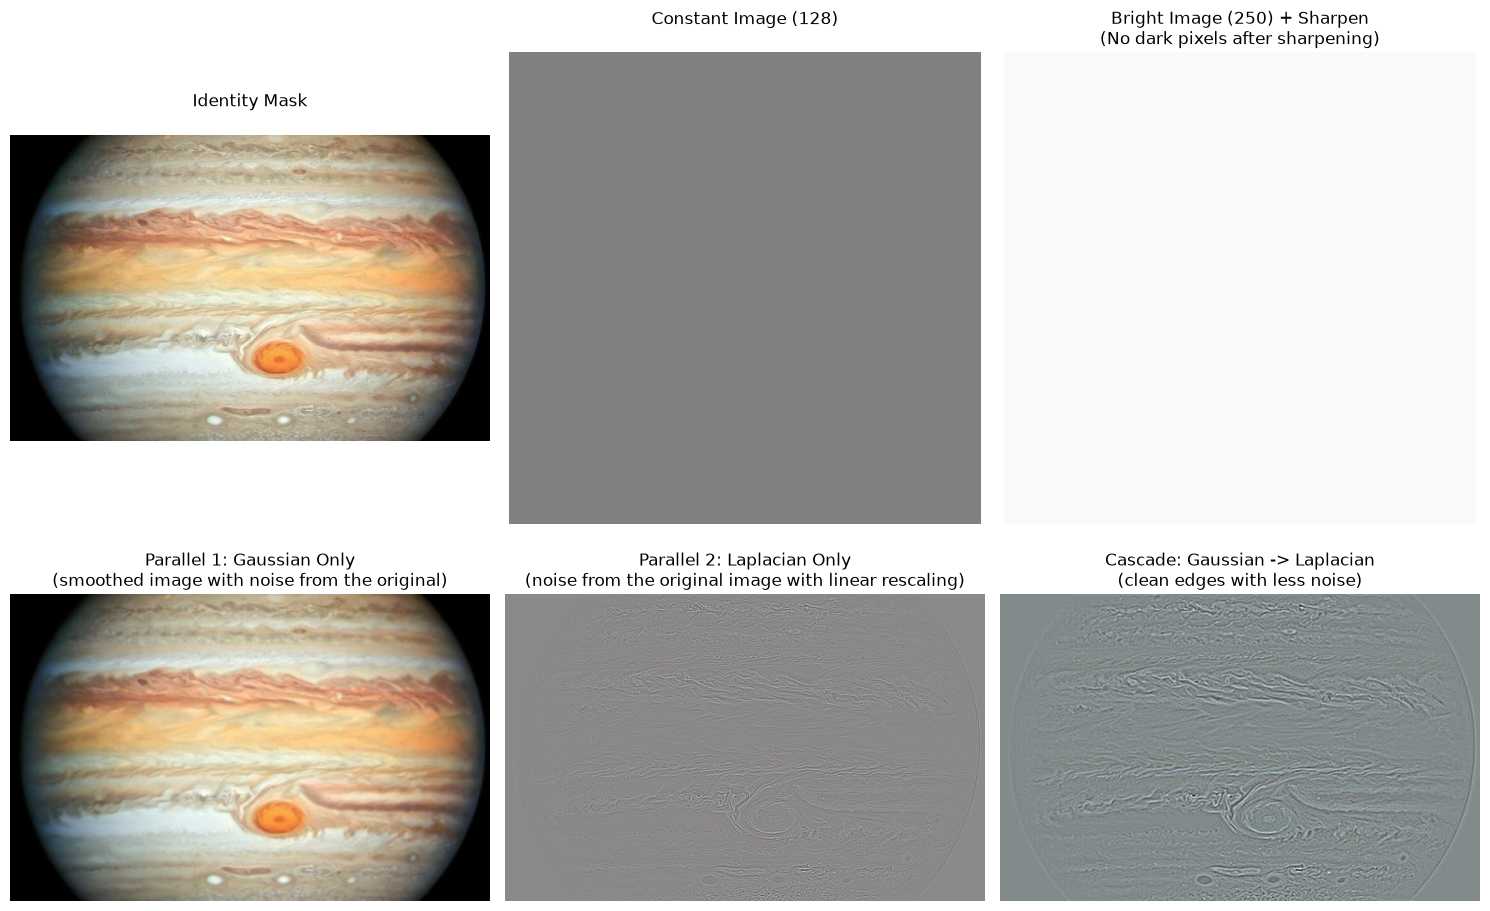

In [24]:
# Visualization of the results
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Test 1: Identity Mask
axes[0, 0].imshow(identity_result)
axes[0, 0].set_title("Identity Mask\n")
axes[0, 0].axis('off')

# Test 2: Constant Image with Replicated Boundary
axes[0, 1].imshow(constant_result)
axes[0, 1].set_title("Constant Image (128)\n")
axes[0, 1].axis('off')

# Test 3: Bright Image with Saturation
axes[0, 2].imshow(bright_result)
axes[0, 2].set_title("Bright Image (250) + Sharpen\n(No dark pixels after sharpening)")
axes[0, 2].axis('off')

# Test 4: Parallel (Gaussian + Laplacian)
axes[1, 0].imshow(parallel_gaussian_laplacian[0])
axes[1, 0].set_title("Parallel 1: Gaussian Only\n(smoothed image with noise from the original)")
axes[1, 0].axis('off')

# Test 5: Parallel (Laplacian only with linear rescaling)
axes[1, 1].imshow(parallel_gaussian_laplacian[1])
axes[1, 1].set_title("Parallel 2: Laplacian Only\n(noise from the original image with linear rescaling)")
axes[1, 1].axis('off')

# Test 6: Cascade (Gaussian -> Laplacian)
axes[1, 2].imshow(cascade_gaussian_laplacian)
axes[1, 2].set_title("Cascade: Gaussian -> Laplacian\n(clean edges with less noise)")
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### Analysis

**Identity Test:** Defines an identity mask, to verify the resultant matrix is the same as the original image. Control test.

**Boundary Replication:** Creates an artificial constant image with all pixels set on a 128 value, and applies a 5x5 mask. It verifies that all of the outputs must be 128, confirming that clamp works well and there is no dark borders (zero padding)

**Saturation and Overflow Protection:**  Creates an artificial image very bright, around 250 , and it applies a sharpening mask that sums 1 but it can multiply local values exceding 250. verifies that the minimum in the image is still 250 or above. Verifies that it doesnt wrap around. 

**Mask Validation and Filtering Effects:** Generates invalid matrixes intentionally (like even numbers, even pairs or out of range) to validate that _validate_mask works well. 

**Linear Rescaling:** Process the real image with gaussian, laplacian and sherpen. prints the resolutions and max and min values, confirming that the liinear reescaling works (even if the laplacian sums 0).

**Library Comparison:** Uses the scipy.ndimage function and compare it with our function. it calculate the rest between mine output image and the scipy output image. The difference is 0 confirming that my implementation generates the same output as the library one.



## Conclusions

The making of this algorithm demostrates the importance of numeric control and memory gestion in image processing. Since in this work we didnt use high level libraries, we could see that the direct manipulation in pixel matrixes can have a lot of visual problems, like wraping-around (dark pixels in bright zones) or dark borders appearing. Doing the partial calculations in a higher precision data type and applying scaling or saturation only at the end was very important to keep the original quality of the image. Also, stretching the borders was better in this case than zero padding. 

In paralel design, i didnt use locks in the shared memory, because the memory array shares giving each process an exclusive group of rows. No worker can modify a pixel at the same time that other, so its impossible to have a race condition. Not using locks makes the code simplier and faster, because the processes dont have to wait for turns. 

The visual tests showed the importance of how filters affect real data. Waterfall filter verified that the order of execution is crucial, applying a gaussian filter first is necessary to erase grain or noise, so the border detector (laplacian) can find the real borders instead of resalting imperfections. Paralel processing proved that is excelent to process and compare how two mathematical operations can  transform the same image at the same time. 